# 02 · Currency, payment amounts, time (and geography)
Feature groups: **Currency Patterns**, **Payment Amount Patterns**, **Temporal Patterns**, plus a **Country / Geography** group the official examples point to.
Unlabelled payments only (`ANOMALY='NONE'`, no recorded anomaly) unless stated; anomalies are studied in notebook 03.

In [21]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## A. Payment amounts
### H-A1  Amounts are log-normal, and each *business* party multiplies the typical amount by a constant factor

In [22]:
amt = q('''SELECT FLOW, count(*) n, median(USD_AMOUNT) median_usd, avg(LOG10_USD) mean_log10, stddev(LOG10_USD) sd_log10,
                  skewness(LOG10_USD) skew, kurtosis(LOG10_USD) excess_kurtosis
           FROM f WHERE NOT IS_ANOMALY GROUP BY 1 ORDER BY 1'''); export(amt,'amount_by_flow'); amt

,FLOW,n,median_usd,mean_log10,sd_log10,skew,excess_kurtosis
0,B2B,2269885,22883.000,4.342040,0.992444,-0.118707,0.082110
1,B2C,5600965,3117.510,3.471822,0.991873,-0.120168,0.085501
2,C2B,609762,3236.315,3.486185,0.992360,-0.117212,0.083436
3,C2C,1512382,463.650,2.632847,0.995531,-0.131053,0.148584


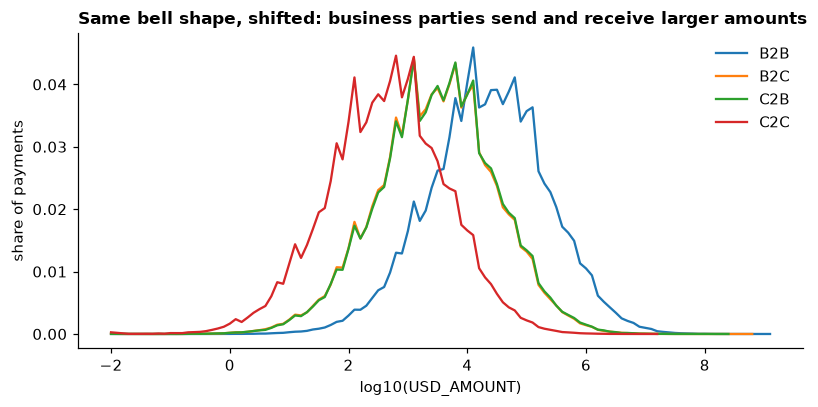

In [23]:
h = q('''SELECT FLOW, round(LOG10_USD*10)/10 lg, count(*) n FROM f WHERE NOT IS_ANOMALY GROUP BY ALL ORDER BY 1,2''')
fig, ax = plt.subplots(figsize=(7.5,3.8))
for flow, g in h.groupby('FLOW'): ax.plot(g.lg, g.n/g.n.sum(), label=flow)
ax.set_xlabel('log10(USD_AMOUNT)'); ax.set_ylabel('share of payments'); ax.legend(frameon=False)
ax.set_title('Same bell shape, shifted: business parties send and receive larger amounts'); savefig('A1_amount_by_flow')

In [24]:
# additive model on the log scale: mean_log10 = base + a*[sender is B] + b*[receiver is B]
m = amt.set_index('FLOW').mean_log10
print('sender B effect  (receiver C):', round(m.B2C-m.C2C,3), '| (receiver B):', round(m.B2B-m.C2B,3))
print('receiver B effect (sender C):', round(m.C2B-m.C2C,3), '| (sender B):', round(m.B2B-m.B2C,3))
print('interaction (0 = purely additive):', round(m.B2B-m.B2C-m.C2B+m.C2C,3))
print('factor per business party ≈ x', round(10**((m.B2B-m.C2C)/2),2))

sender B effect  (receiver C): 0.839 | (receiver B): 0.856
receiver B effect (sender C): 0.853 | (sender B): 0.87
interaction (0 = purely additive): 0.017
factor per business party ≈ x 7.15


Confounder check: does the business effect hold inside every currency (Simpson's-paradox check)?

In [25]:
bycc = q('''SELECT CURRENCY_CODE, count(*) n,
                   avg(LOG10_USD) FILTER (FLOW='B2B') - avg(LOG10_USD) FILTER (FLOW='C2C') AS b2b_minus_c2c,
                   avg(LOG10_USD) FILTER (FLOW='B2C') - avg(LOG10_USD) FILTER (FLOW='C2C') AS b2c_minus_c2c,
                   stddev(LOG10_USD) FILTER (FLOW='B2C') AS sd_within
            FROM f WHERE NOT IS_ANOMALY GROUP BY 1 HAVING count(*)>=20000 ORDER BY n DESC''')
print(bycc[['b2b_minus_c2c','b2c_minus_c2c','sd_within']].describe().loc[['mean','std','min','max']]); bycc.head(12)

      b2b_minus_c2c  b2c_minus_c2c  sd_within
mean       1.738029       0.868112   0.920412
std        0.084821       0.087014   0.020410
min        1.544617       0.660480   0.882849
max        1.946897       1.092504   1.001986


,CURRENCY_CODE,n,b2b_minus_c2c,b2c_minus_c2c,sd_within
0,EUR,3197037,1.707181,0.833557,0.951244
1,USD,1702039,1.754630,0.885925,0.934252
2,GBP,873422,1.690033,0.808061,0.934565
3,CHF,803526,1.671261,0.793808,0.915924
4,SGD,367461,1.776664,0.902864,0.911219
5,CNY,324396,1.724568,0.852297,0.926792
6,HKD,197371,1.701054,0.837819,0.908908
7,JPY,184136,1.747910,0.890872,0.911953
8,AUD,166788,1.750600,0.869512,0.917721
9,CAD,111069,1.730150,0.854345,0.904978


### H-A2  Round amounts are chosen in the *payment currency* (so they only show up as round numbers for USD)

In [26]:
rnd = q('''SELECT CURRENCY_CODE='USD' AS is_usd, count(*) n,
                  avg((round(USD_AMOUNT*100)::bigint % 100 = 0)::int) AS share_whole_units,
                  avg((round(USD_AMOUNT)::bigint % 100 = 0 AND round(USD_AMOUNT*100)::bigint % 100 = 0)::int) AS share_multiple_of_100
           FROM f WHERE NOT IS_ANOMALY GROUP BY 1'''); export(rnd,'amount_roundness'); rnd

,is_usd,n,share_whole_units,share_multiple_of_100
0,False,8290955,0.009885,0.000144
1,True,1702039,0.386362,0.155458


In [27]:
q('''SELECT FLOW, avg((round(USD_AMOUNT*100)::bigint % 100 = 0)::int) AS share_whole_units, count(*) n
     FROM f WHERE NOT IS_ANOMALY AND CURRENCY_CODE='USD' GROUP BY 1 ORDER BY 1''')

,FLOW,share_whole_units,n
0,B2B,0.387665,405293
1,B2C,0.386784,956300
2,C2B,0.385073,100890
3,C2C,0.383017,239556


In [28]:
q('''SELECT USD_AMOUNT, count(*) n FROM f WHERE CURRENCY_CODE='USD' AND NOT IS_ANOMALY GROUP BY 1 ORDER BY n DESC LIMIT 15''').T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
USD_AMOUNT,10000.0,1000.0,5000.0,100000.0,500.0,100.0,50000.0,2000.0,50.0,20000.0,3000.0,2500.0,500000.0,4000.0,25000.0
n,35590.0,32551.0,21666.0,16979.0,15492.0,13620.0,13110.0,5511.0,5108.0,4545.0,4373.0,4237.0,3492.0,3425.0,3419.0


## B. Currency
### H-B1  Each currency has its own amount level (a per-currency shift on the log scale), on top of the flow effect

In [29]:
cur = q('''SELECT CURRENCY_CODE, count(*) n, count(*)/sum(count(*)) OVER () AS share,
                  median(USD_AMOUNT) median_usd, avg(LOG10_USD) mean_log10
           FROM f WHERE NOT IS_ANOMALY GROUP BY 1 ORDER BY n DESC'''); export(cur,'currency_overview'); cur.head(15)

,CURRENCY_CODE,n,share,median_usd,mean_log10
0,EUR,3197037,0.319928,4602.440,3.640510
1,USD,1702039,0.170323,6371.000,3.789820
2,GBP,873422,0.087403,3584.505,3.549853
3,CHF,803526,0.080409,6097.470,3.761881
4,SGD,367461,0.036772,6402.250,3.787814
5,CNY,324396,0.032462,1349.010,3.118982
6,HKD,197371,0.019751,4891.310,3.669066
7,JPY,184136,0.018427,2813.610,3.420393
8,AUD,166788,0.016690,4621.385,3.656708
9,CAD,111069,0.011115,4704.990,3.666032


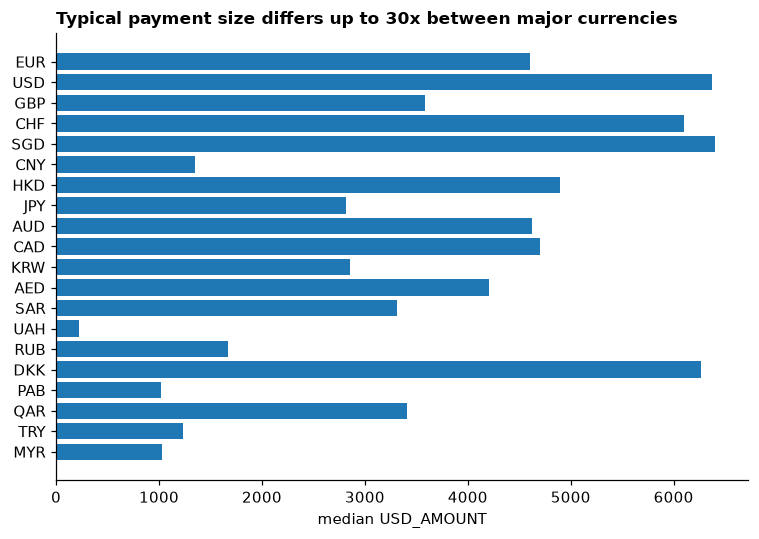

In [30]:
top = cur.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7,5)); ax.barh(top.CURRENCY_CODE, top.median_usd)
ax.set_xlabel('median USD_AMOUNT'); ax.set_title('Typical payment size differs up to 30x between major currencies'); savefig('B1_median_by_currency')

### H-B2  Which currency is used depends on the two countries: mostly the sender's or receiver's home currency, otherwise a vehicle currency (USD/EUR)

In [31]:
# data-driven 'home currency' of a country = most frequent currency of its DOMESTIC payments
home = q('''SELECT ORD_COUNTRY country, arg_max(CURRENCY_CODE, n) home_ccy, max(n)/sum(n) AS share_home_in_domestic, sum(n) n_domestic
            FROM (SELECT ORD_COUNTRY, CURRENCY_CODE, count(*) n FROM f WHERE IS_DOMESTIC AND NOT IS_ANOMALY GROUP BY ALL) GROUP BY 1''')
from utils import con; con.register('home', home); export(home,'country_home_currency')
print(home.share_home_in_domestic.describe()); home.sort_values('n_domestic', ascending=False).head(10)

count    124.000000
mean       0.883088
std        0.139092
min        0.333333
25%        0.839015
50%        0.922195
75%        1.000000
max        1.000000
Name: share_home_in_domestic, dtype: float64


,country,home_ccy,share_home_in_domestic,n_domestic
4,US,USD,0.939328,385481.0
3,CH,CHF,0.924305,77020.0
1,GB,GBP,0.931730,64977.0
0,DE,EUR,0.963467,34489.0
67,FR,EUR,0.955468,32763.0
75,SG,SGD,0.922594,21329.0
13,CN,CNY,0.919324,19597.0
74,IT,EUR,0.959244,12906.0
76,LU,EUR,0.959744,10458.0
2,BE,EUR,0.950118,9723.0


In [32]:
ccy_rule = q('''SELECT IS_DOMESTIC,
        CASE WHEN CURRENCY_CODE=ho.home_ccy AND CURRENCY_CODE=hb.home_ccy THEN '1 both home'
             WHEN CURRENCY_CODE=ho.home_ccy THEN '2 sender home' WHEN CURRENCY_CODE=hb.home_ccy THEN '3 receiver home'
             WHEN CURRENCY_CODE IN ('USD','EUR') THEN '4 USD/EUR vehicle' ELSE '5 other' END AS currency_choice, count(*) n
     FROM f LEFT JOIN home ho ON ho.country=ORD_COUNTRY LEFT JOIN home hb ON hb.country=BEN_COUNTRY
     WHERE NOT IS_ANOMALY GROUP BY ALL ORDER BY 1,2''')
ccy_rule['share'] = ccy_rule.n / ccy_rule.groupby('IS_DOMESTIC').n.transform('sum'); export(ccy_rule,'currency_choice_rule'); ccy_rule

,IS_DOMESTIC,currency_choice,n,share
0,False,1 both home,805431,0.086772
1,False,2 sender home,7240949,0.780092
2,False,3 receiver home,430740,0.046405
3,False,4 USD/EUR vehicle,336237,0.036224
4,False,5 other,468813,0.050507
5,True,1 both home,666439,0.937558
6,True,4 USD/EUR vehicle,27136,0.038175
7,True,5 other,17249,0.024266


## C. Time
### H-C1  Volume follows the business week: weekends carry a fraction of weekday volume, for consumers too

In [33]:
dow = q('''SELECT DOW, ORDERING_TYPE, count(*)/count(DISTINCT DATE_UTC) AS payments_per_day FROM f GROUP BY ALL ORDER BY 2,1''')
piv = dow.pivot(index='DOW', columns='ORDERING_TYPE', values='payments_per_day'); piv['B_vs_weekday'] = piv.B/piv.B[:5].mean(); piv['C_vs_weekday'] = piv.C/piv.C[:5].mean()
export(piv.reset_index(),'time_day_of_week'); piv

ORDERING_TYPE,B,C,B_vs_weekday,C_vs_weekday
DOW,,,,
1,103225.285714,27752.214286,0.973575,0.970467
2,103489.153846,27932.384615,0.976064,0.976767
3,103269.769231,27854.461538,0.973995,0.974042
4,109130.538462,29411.153846,1.029271,1.028478
5,111020.384615,30033.615385,1.047095,1.050245
6,26256.230769,7200.307692,0.247637,0.251787
7,38451.714286,10372.642857,0.362660,0.362721


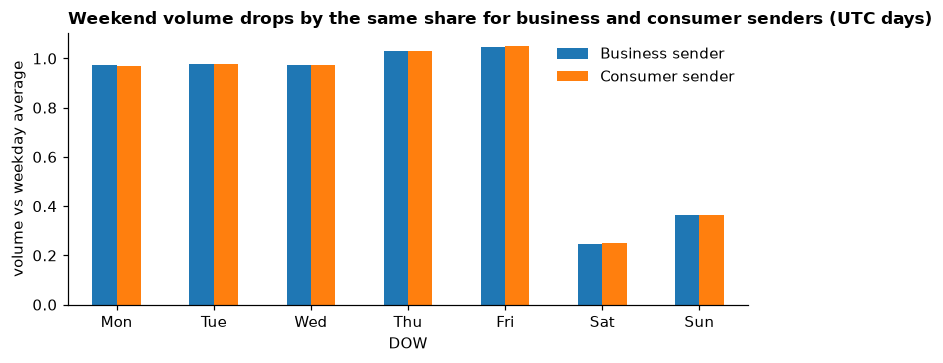

In [34]:
fig, ax = plt.subplots(figsize=(7,3.4)); piv[['B_vs_weekday','C_vs_weekday']].plot.bar(ax=ax)
ax.set_xticklabels(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], rotation=0); ax.set_ylabel('volume vs weekday average'); ax.legend(['Business sender','Consumer sender'], frameon=False)
ax.set_title('Weekend volume drops by the same share for business and consumer senders (UTC days)'); savefig('C1_day_of_week')

### H-C2  Activity follows the *sender's local* clock: the daily curve is the same shape in every country, shifted by the time zone
We estimate each country's shift from the data (circular mean of the hour), not from an external time-zone table.

In [35]:
hr = q('''SELECT ORD_COUNTRY, HOUR_UTC, count(*) n FROM f WHERE NOT IS_WEEKEND GROUP BY ALL''')
big = hr.groupby('ORD_COUNTRY').n.sum().nlargest(40).index
ang = 2*np.pi*hr.HOUR_UTC/24
cm = hr.assign(s=hr.n*np.sin(ang), c=hr.n*np.cos(ang)).groupby('ORD_COUNTRY')[['s','c','n']].sum()
cm['centre_hour_utc'] = (np.arctan2(cm.s, cm.c)*24/(2*np.pi)) % 24
cm['concentration'] = np.hypot(cm.s, cm.c)/cm.n
export(cm.loc[big].reset_index(),'time_country_centre_hour'); cm.loc[big].sort_values('centre_hour_utc')[['n','centre_hour_utc','concentration']].round(2).T

ORD_COUNTRY,AU,KR,JP,CN,SG,HK,MY,IN,AE,TR,SA,RU,QA,ZA,IL,FI,NL,UA,ES,AT,BE,DE,DK,CH,MC,FR,LU,IT,CZ,PL,LI,GB,JE,IE,IM,AR,CA,US,KY,PA
n,156513.00,103703.00,167453.00,299921.00,344516.00,184018.00,49630.00,50037.00,95587.00,52000.00,92134.00,78749.00,58713.00,42810.00,45133.00,137319.00,189313.00,65281.0,136053.00,96016.00,265466.00,457239.00,60723.00,705373.00,44151.00,483677.00,260877.00,267717.00,38528.00,39395.00,52624.00,596048.00,45775.00,62843.00,161997.00,45071.00,108898.00,1383232.00,38653.00,59310.00
centre_hour_utc,3.86,5.80,5.91,6.61,6.74,6.78,7.13,9.05,10.28,11.36,11.36,11.54,11.89,12.26,12.78,13.07,13.24,13.3,13.35,13.36,13.37,13.41,13.45,13.46,13.46,13.49,13.49,13.49,13.51,13.83,13.90,14.46,14.55,14.61,14.71,16.97,19.04,19.05,19.27,19.52
concentration,0.33,0.34,0.33,0.34,0.33,0.33,0.33,0.32,0.33,0.32,0.32,0.32,0.30,0.33,0.31,0.30,0.33,0.3,0.32,0.33,0.32,0.32,0.32,0.32,0.32,0.32,0.31,0.32,0.32,0.31,0.31,0.32,0.31,0.31,0.31,0.33,0.32,0.32,0.30,0.30


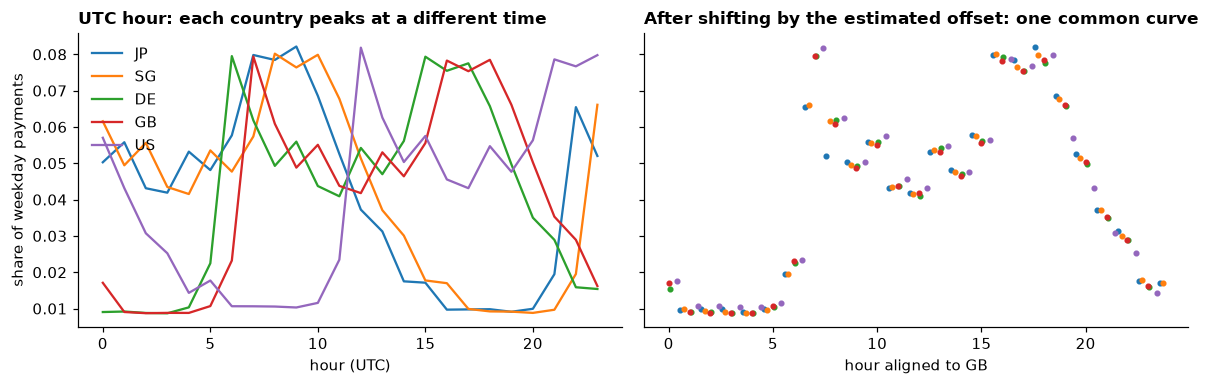

In [36]:
fig, axes = plt.subplots(1,2, figsize=(11,3.6), sharey=True)
show = ['JP','SG','DE','GB','US']
for c in show:
    g = hr[hr.ORD_COUNTRY==c].sort_values('HOUR_UTC'); axes[0].plot(g.HOUR_UTC, g.n/g.n.sum(), label=c)
    shift = (cm.centre_hour_utc[c] - cm.centre_hour_utc['GB'])
    axes[1].plot((g.HOUR_UTC - shift) % 24, g.n/g.n.sum(), '.', label=c)
axes[0].set_title('UTC hour: each country peaks at a different time'); axes[1].set_title('After shifting by the estimated offset: one common curve')
axes[0].set_xlabel('hour (UTC)'); axes[1].set_xlabel('hour aligned to GB'); axes[0].set_ylabel('share of weekday payments'); axes[0].legend(frameon=False)
savefig('C2_local_time_alignment')

In [37]:
# does the hourly shape differ between business and consumer senders? (GB = offset ~0)
q('''SELECT HOUR_UTC, round(100.0*sum((ORDERING_TYPE='B')::int)/sum(sum((ORDERING_TYPE='B')::int)) OVER (),2) AS pct_of_B,
            round(100.0*sum((ORDERING_TYPE='C')::int)/sum(sum((ORDERING_TYPE='C')::int)) OVER (),2) AS pct_of_C
     FROM f WHERE ORD_COUNTRY='GB' AND NOT IS_WEEKEND GROUP BY 1 ORDER BY 1''').T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
HOUR_UTC,0.00,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.00,11.00,12.0,13.00,14.00,15.00,16.00,17.00,18.00,19.00,20.00,21.00,22.00,23.00
pct_of_B,1.69,0.89,0.87,0.88,0.88,1.06,2.34,7.91,6.19,4.95,5.58,4.39,4.2,5.34,4.72,5.62,7.98,7.52,7.73,6.49,4.90,3.47,2.81,1.59
pct_of_C,1.77,0.95,0.87,0.89,0.88,1.09,2.26,8.05,5.72,4.63,5.26,4.32,4.1,5.16,4.34,5.32,7.28,7.59,8.29,7.07,5.48,3.74,3.19,1.73


,count,mean,min,25%,50%,75%,max,std
DATE_UTC,93,2023-06-15 00:00:00,2023-04-30 00:00:00,2023-05-23 00:00:00,2023-06-15 00:00:00,2023-07-08 00:00:00,2023-07-31 00:00:00,NaN
n,93.0,107526.88172,2311.0,57225.0,109549.0,152956.0,220212.0,54531.808027


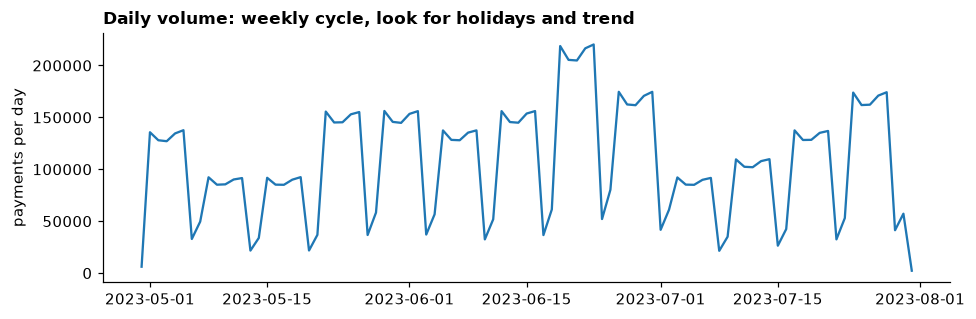

In [38]:
# trend across the 3 months: daily volume
d = q('SELECT DATE_UTC, count(*) n FROM f GROUP BY 1 ORDER BY 1')
fig, ax = plt.subplots(figsize=(9,3)); ax.plot(d.DATE_UTC, d.n); ax.set_ylabel('payments per day')
ax.set_title('Daily volume: weekly cycle, look for holidays and trend'); savefig('C3_daily_volume'); export(d,'time_daily_volume').describe().T

## D. Geography
### H-D1  A few corridors carry most payments; domestic payments are the exception

In [39]:
geo = q('''SELECT ORD_COUNTRY, count(*) n_sent, avg(IS_DOMESTIC::int) share_domestic, median(USD_AMOUNT) median_usd,
                  avg((ORDERING_TYPE='B')::int) share_business_senders FROM f GROUP BY 1 ORDER BY n_sent DESC''')
export(geo,'geo_sending_countries'); print('countries:', len(geo)); geo.head(15)

countries: 228


,ORD_COUNTRY,n_sent,share_domestic,median_usd,share_business_senders
0,US,1582415,0.243677,7416.000,0.805753
1,CH,786246,0.097978,6058.240,0.749940
2,GB,662529,0.098098,3882.390,0.785993
3,FR,538746,0.060826,4158.810,0.799215
4,DE,509341,0.067729,5178.330,0.781822
5,SG,393191,0.054246,6640.100,0.791524
6,CN,342194,0.057432,1201.570,0.860486
7,IT,298586,0.043257,3371.410,0.813809
8,BE,295928,0.032863,6304.405,0.809984
9,LU,290106,0.036059,10929.545,0.771084


In [40]:
# is the receiving country chosen independently of the sending country? observed vs expected under independence
od = q('''SELECT ORD_COUNTRY o, BEN_COUNTRY b, count(*) n FROM f GROUP BY ALL''')
tot = od.n.sum(); od['expected'] = od.groupby('o').n.transform('sum') * od.groupby('b').n.transform('sum') / tot
od['lift'] = od.n / od.expected; export(od.sort_values('n', ascending=False).head(300),'geo_corridors_top300')
od[od.n>20000].sort_values('lift', ascending=False).head(15)

,o,b,n,expected,lift
2277,MQ,TN,20007,84.154294,237.741879
77,GB,GB,64993,43870.417781,1.481477
68,SG,SG,21329,15355.484718,1.389015
2104,DE,DE,34497,26624.018081,1.295710
2048,US,US,385598,304462.184453,1.266489
2217,US,NL,38150,30512.600754,1.250303
2363,NL,CH,21459,17487.961645,1.227073
120,CH,CH,77035,65286.408358,1.179955
70,LU,US,65393,55817.409771,1.171552
2057,SG,US,87910,75651.324569,1.162042
